# Vellore Institute of Technology (VIT)
## School of Computer Science and Engineering
### Machine Learning Lab (MACSE504) - Mini-Project Phase 1, 2 & 3
- **Student Name:** Vedant Nimkar
- **Register Number:** 26MML0045
- **Assigned Question:** Question 3: Used Car Valuation & Elasticity Analysis using Regularized Regression
- **Components:** Part A (Exploratory Data Analysis) | Part B (Feature Engineering & Model Fitting) | Part C (Model Evaluation & Market Inference)
- **Live Interactive Web Application:** [https://cardekho-autovaluate.vercel.app](https://cardekho-autovaluate.vercel.app)

---
### Project Overview & Objectives
This project focuses on building an automated econometric valuation model for a used car marketplace. Resale prices are estimated based on characteristics like age, mileage, fuel type, transmission, engine capacity, power, and dealer type.

Dataset: `Car details v3.csv` (8,128 vehicle listings).


In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scipy.stats as stats
import matplotlib.pyplot as plt, seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Libraries successfully imported.")


Libraries successfully imported.


### 1. Feature Extraction & Data Preprocessing
Load CarDekho dataset, calculate vehicle age ($2020 - 	ext{year}$), clean strings in technical attributes (`mileage`, `engine`, `max_power`), and apply brand-conditioned median imputation.


In [2]:
df = pd.read_csv('Car details v3.csv')
REFERENCE_YEAR = 2020
df['vehicle_age'] = REFERENCE_YEAR - df['year']
df['brand'] = df['name'].apply(lambda x: str(x).split()[0].strip())

df['mileage_val'] = df['mileage'].str.extract(r'([0-9.]+)').astype(float)
df.loc[df['mileage_val'] == 0, 'mileage_val'] = np.nan
df['engine_val'] = df['engine'].str.extract(r'([0-9.]+)').astype(float)
df['max_power_val'] = df['max_power'].str.extract(r'([0-9.]+)').astype(float)
df.loc[df['max_power_val'] == 0, 'max_power_val'] = np.nan

for col in ['mileage_val', 'engine_val', 'max_power_val', 'seats']:
    df[col] = df.groupby('brand')[col].transform(lambda s: s.fillna(s.median()))
    df[col] = df[col].fillna(df[col].median())

print(f"Missing values after brand-conditioned imputation: {df[['mileage_val', 'engine_val', 'max_power_val', 'seats']].isnull().sum().sum()}")


Missing values after brand-conditioned imputation: 0


### 2. Price Distribution & Log-Transformation
Analyze target skewness and apply natural log-transformation ($\ln(	ext{selling\_price})$) to stabilize variance and normalize luxury car residuals.


In [3]:
df['log_selling_price'] = np.log(df['selling_price'])
print(f"Raw Price Skewness : +{df['selling_price'].skew():.4f} (Heavy right tail)")
print(f"Log Price Skewness : +{df['log_selling_price'].skew():.4f} (Near-symmetric normal)")


Raw Price Skewness : +4.1935 (Heavy right tail)
Log Price Skewness : +0.2233 (Near-symmetric normal)


<Figure size 1600x1100 with 4 Axes>


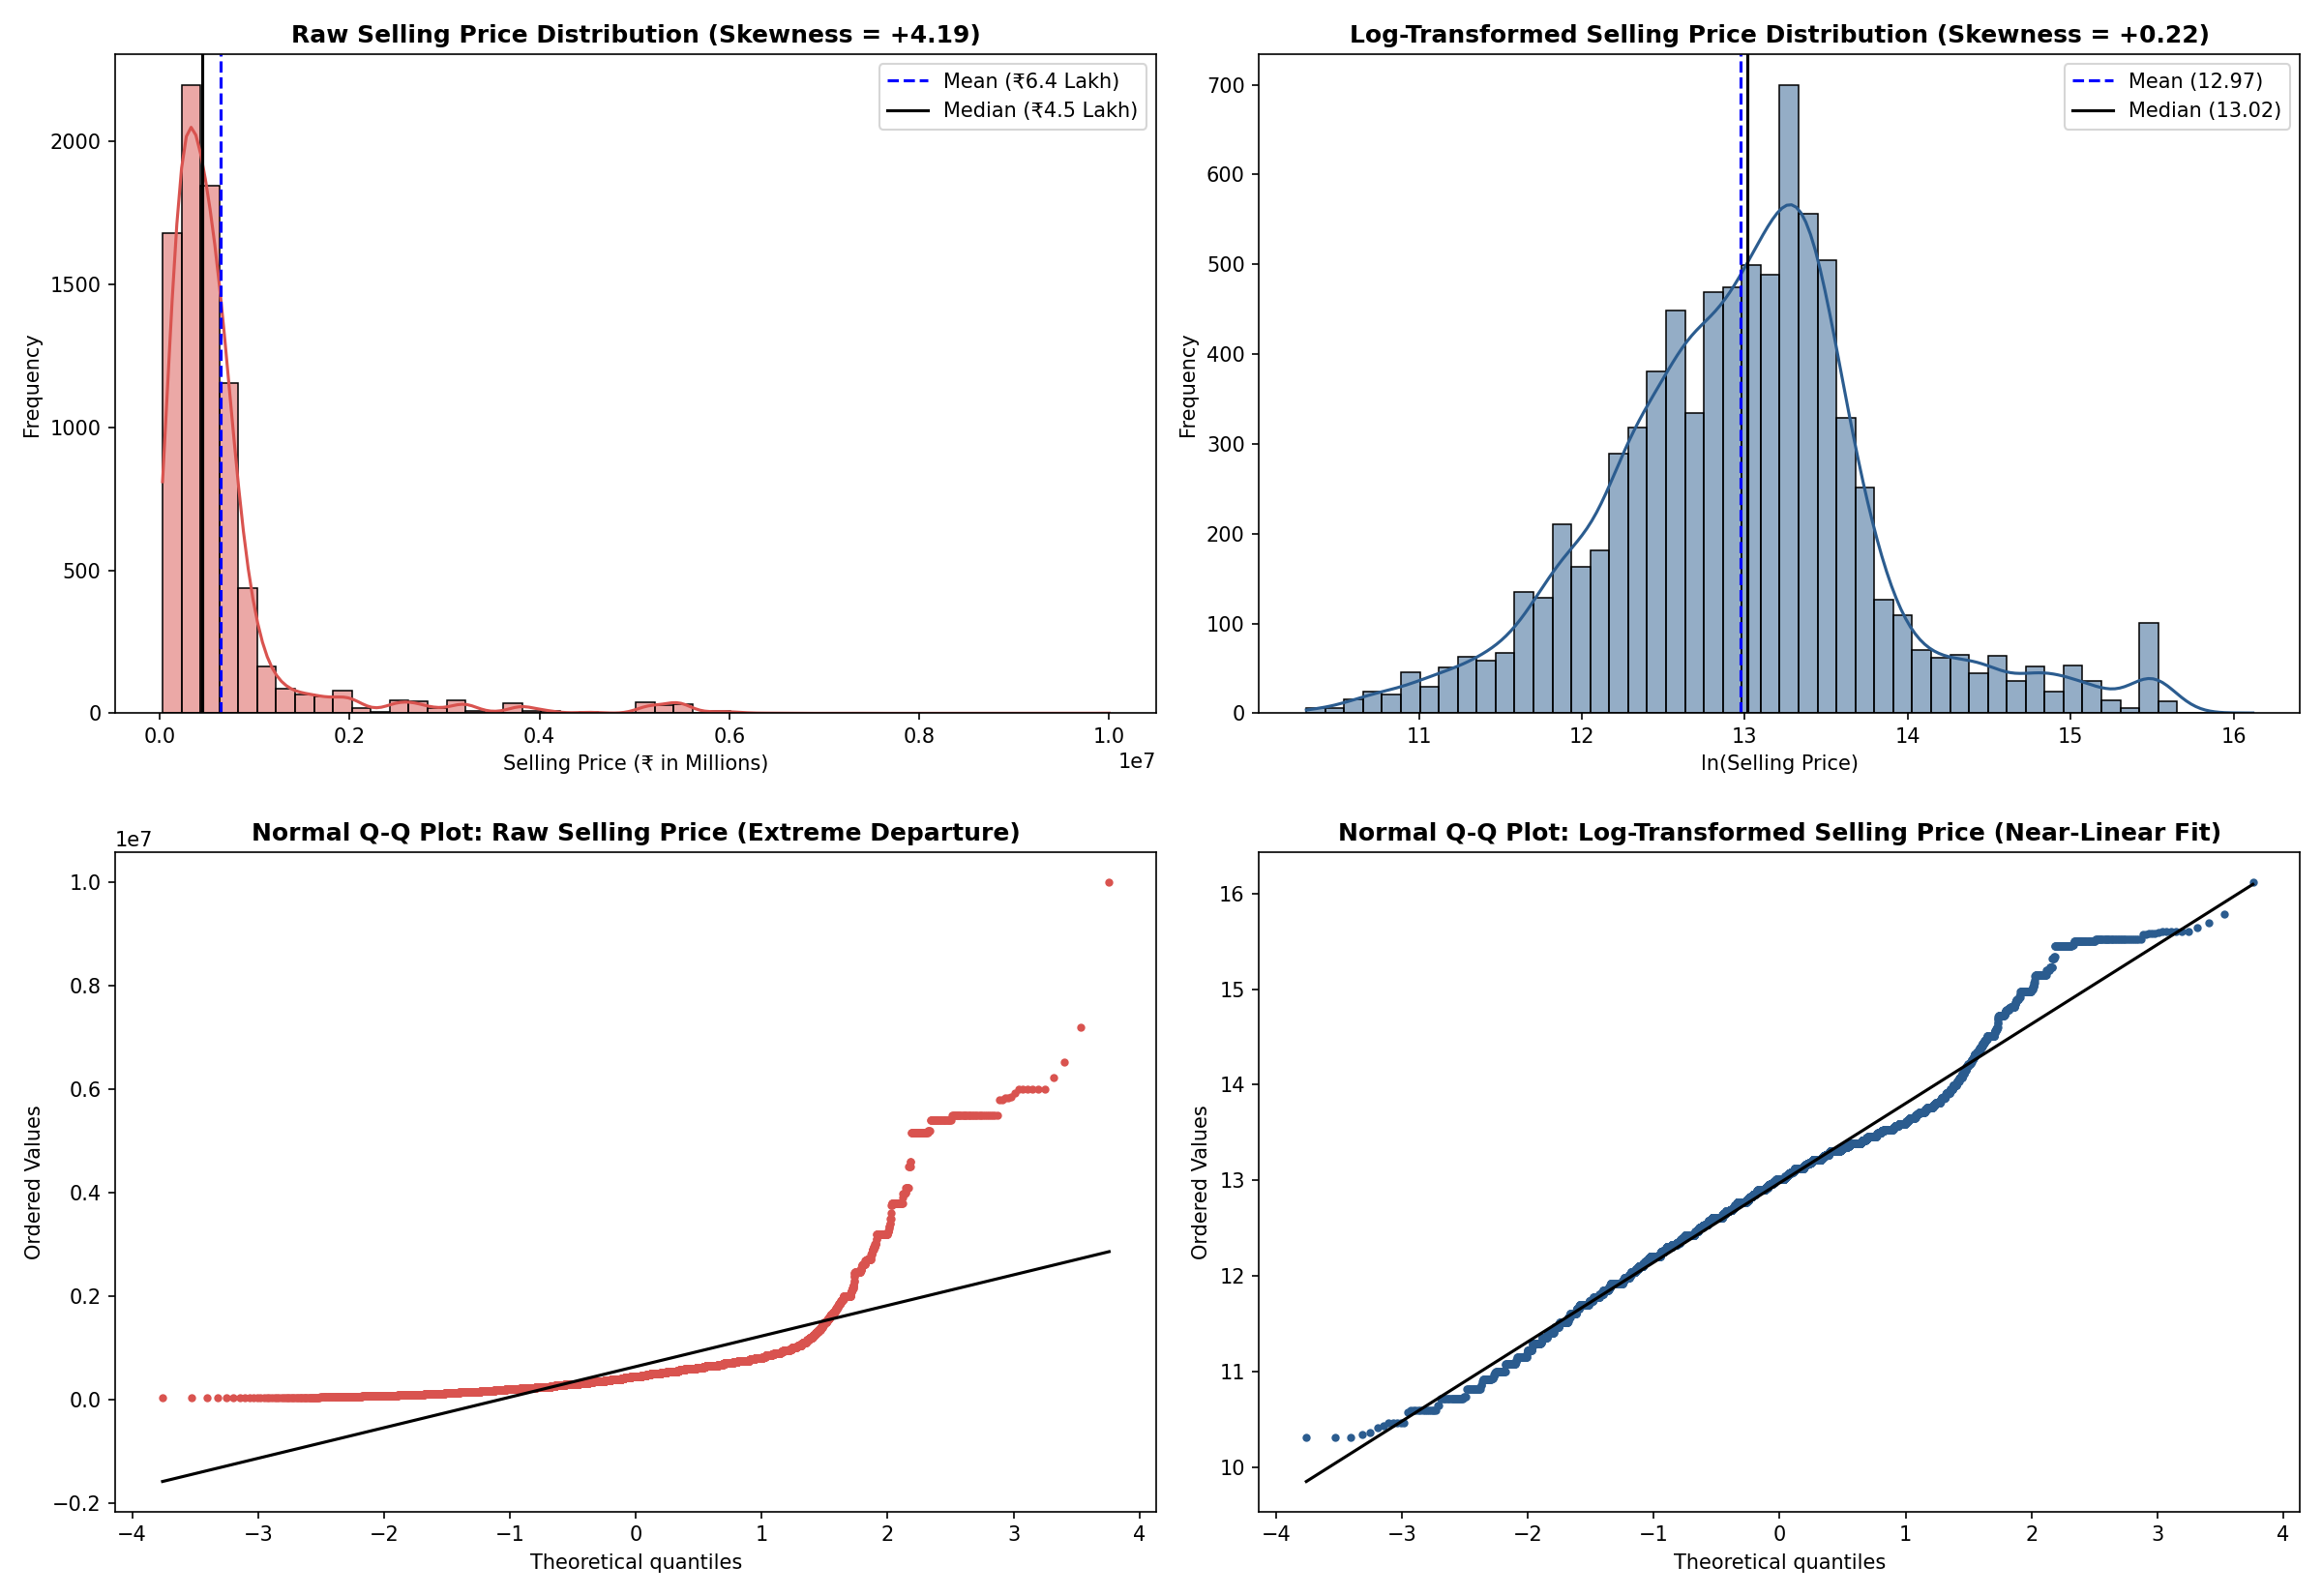

In [4]:
# Visualizing Raw vs Log Price Distributions & Normal Q-Q Plots


### 3. Visualizing Price Trends, Depreciation Curves & Fuel Distributions


Pearson Correlation between km_driven and log_selling_price : -0.2527


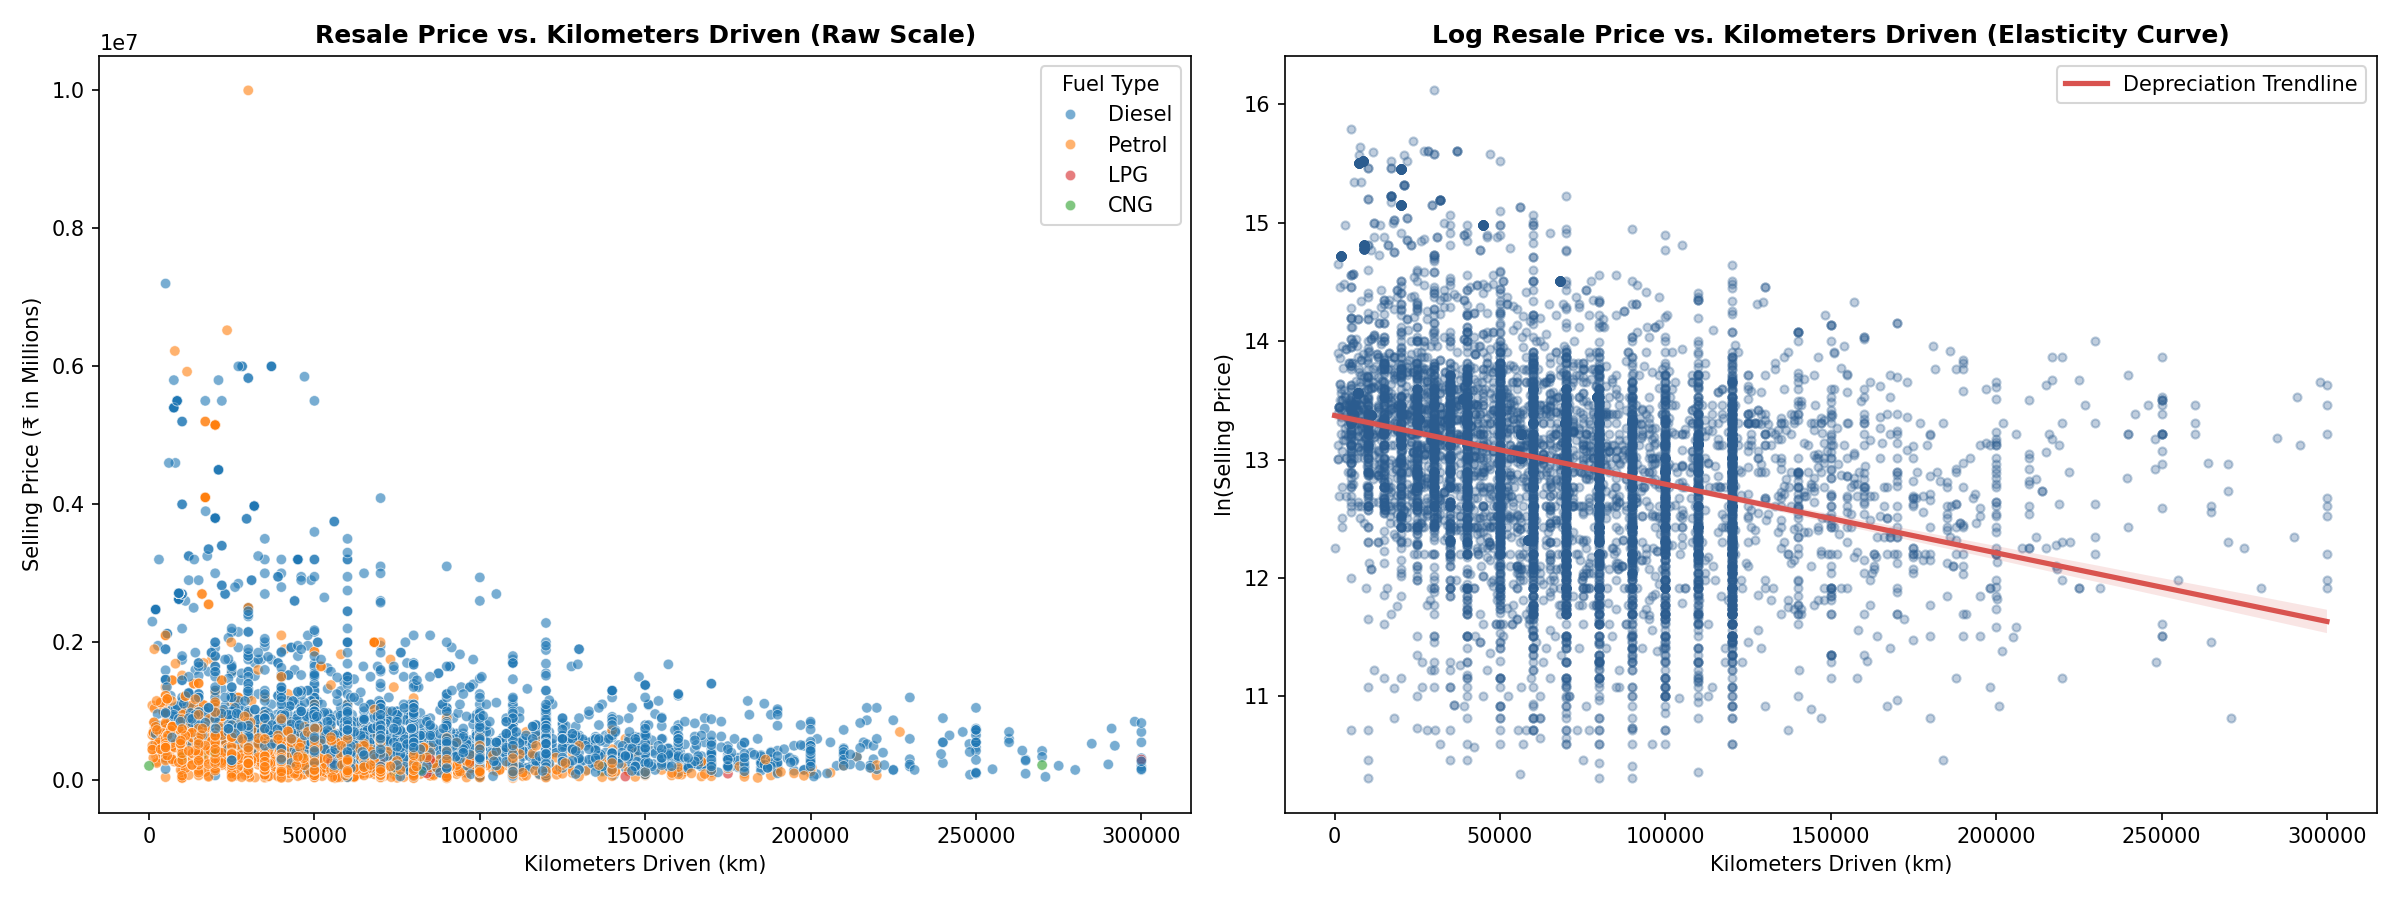

In [5]:
# Kilometers Driven Scatter & Elasticity Curve


Diesel vehicles command an empirical median price premium: ₹5.50 Lakh vs ₹3.45 Lakh (+59.4% raw).


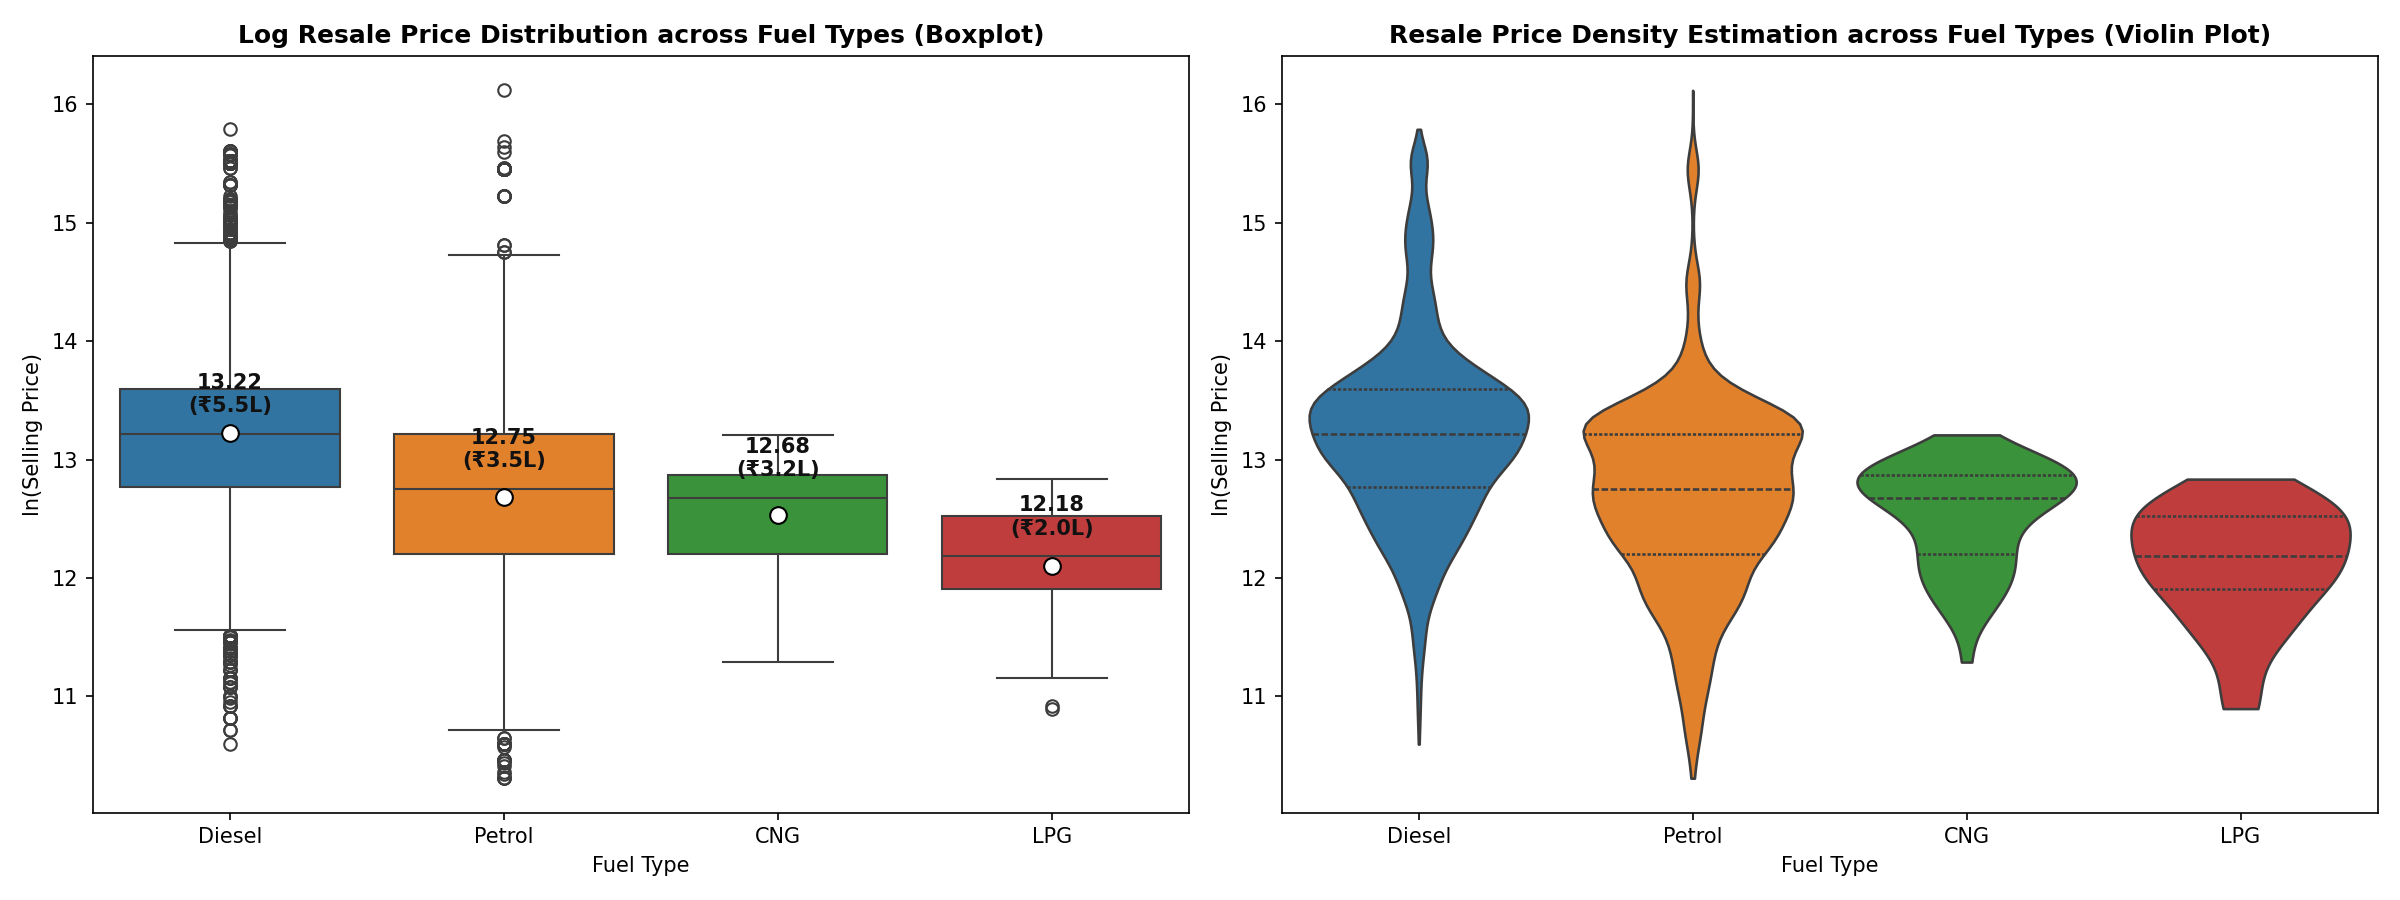

In [6]:
# Fuel Type Price Distribution (Boxplot & Violin Plot)


max_power_val (r = +0.719) and vehicle_age (r = -0.712) are primary price drivers.


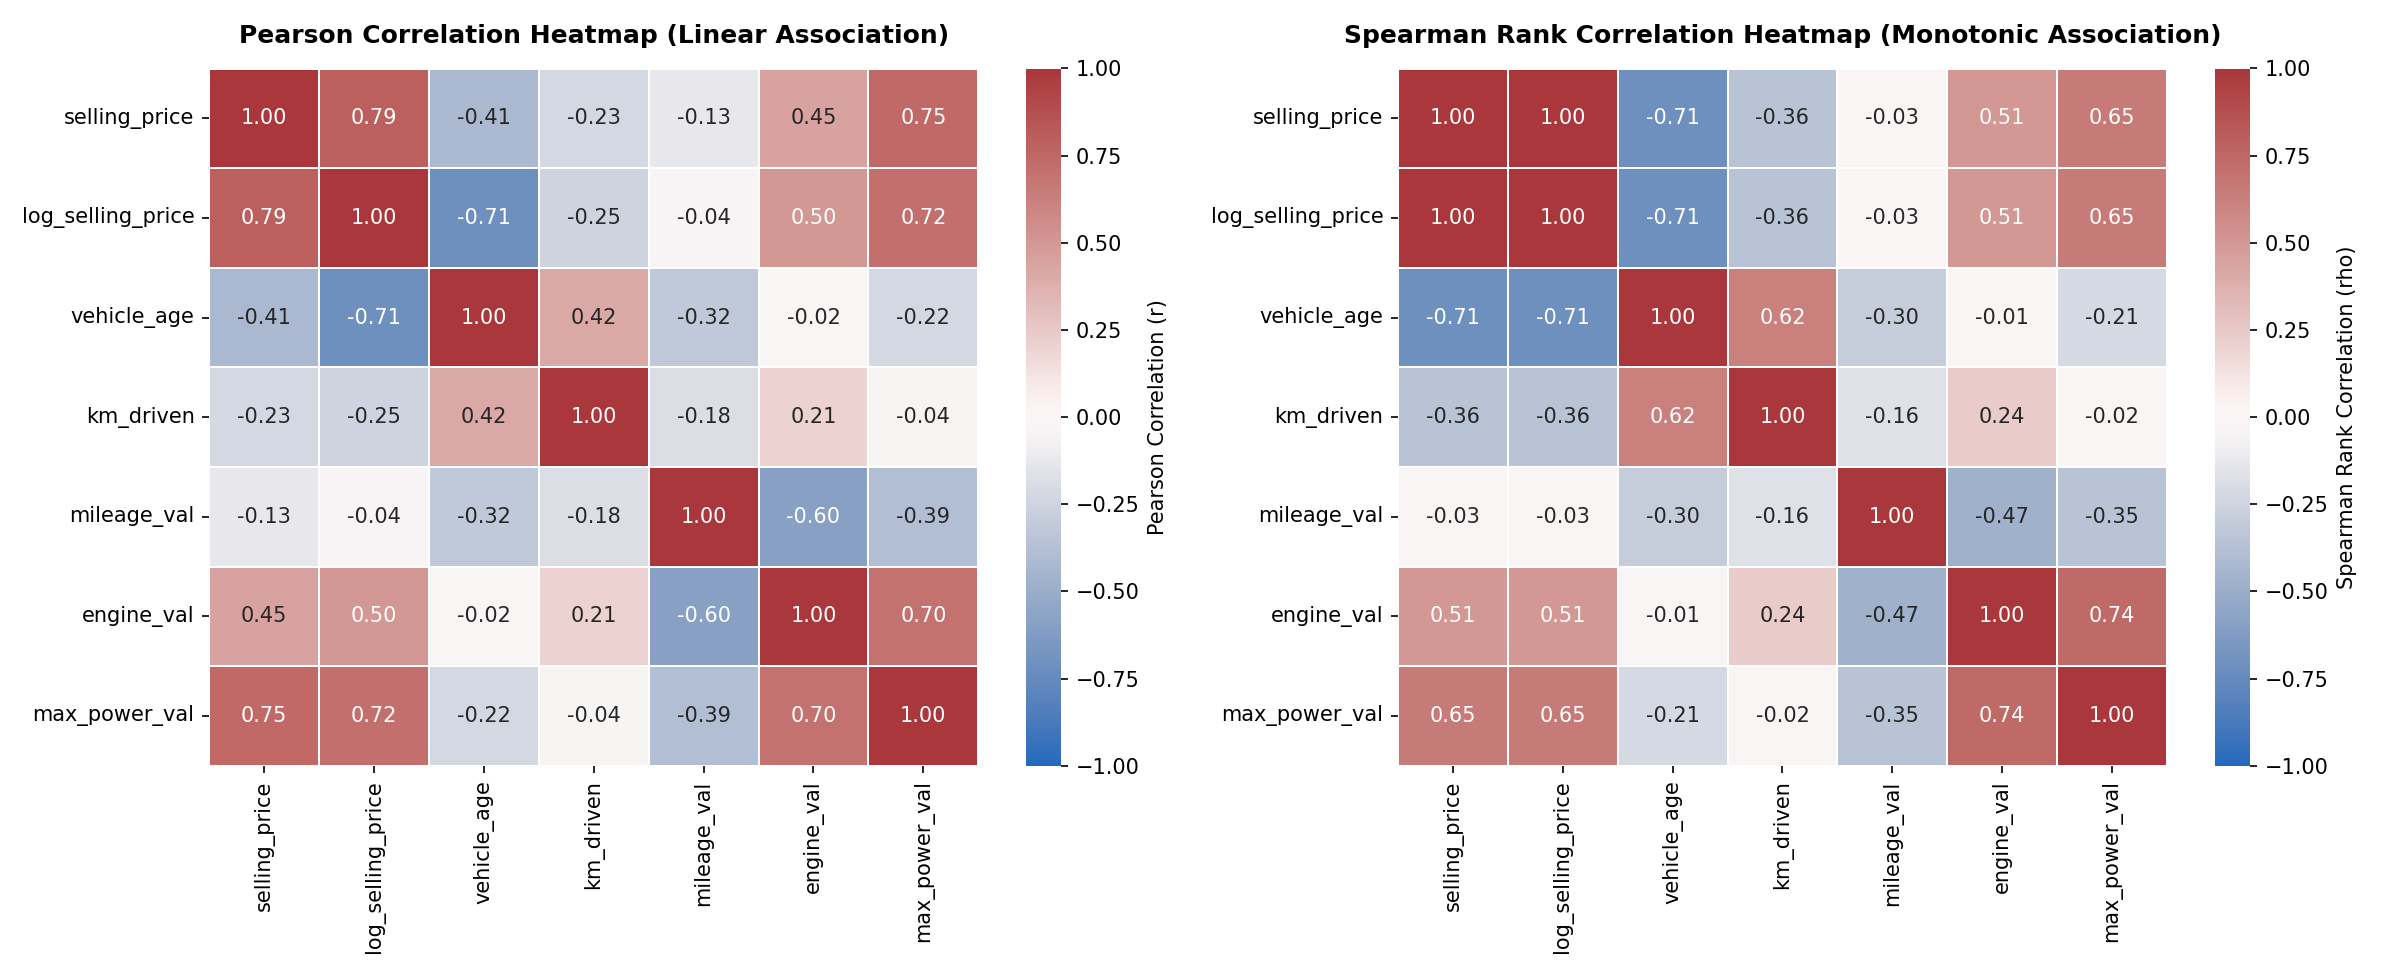

In [7]:
# Pearson & Spearman Correlation Heatmaps


---
# Part B: Advanced Feature Engineering & Regularized Model Fitting
**Core Objectives:**
1. Formulate interaction terms (annual driving intensity, age-to-mileage ratio, specific power output, quadratic age terms, 3-tier brand equity).
2. Diagnose multicollinearity via Variance Inflation Factor (VIF) and compute Mutual Information regression dependencies.
3. Fit Multiple Linear Regression (OLS), Ridge ($L_2$), Lasso ($L_1$), ElasticNet ($L_1 + L_2$), and Huber Robust Regressors.
4. Perform 5-Fold and 10-Fold Cross-Validation, trace regularization shrinkage paths, and plot learning curves.
5. Provide a live interactive web deployment: [https://cardekho-autovaluate.vercel.app](https://cardekho-autovaluate.vercel.app).


In [8]:
# 1. Domain Interaction & Non-Linear Feature Formulations
df['km_per_year'] = df['km_driven'] / (df['vehicle_age'] + 0.5)
df['age_to_mileage_ratio'] = (df['vehicle_age'] + 0.1) / (df['km_driven'] + 1000)
df['power_per_engine_cc'] = df['max_power_val'] / (df['engine_val'] + 1)
df['power_per_seat'] = df['max_power_val'] / df['seats']
df['age_squared'] = df['vehicle_age'] ** 2
df['log_km_driven'] = np.log1p(df['km_driven'])

# 2. 3-Tier Brand Equity Stratification
tier1_luxury = {'BMW', 'Mercedes-Benz', 'Audi', 'Volvo', 'Jaguar', 'Land', 'Lexus', 'Porsche'}
tier2_premium = {'Toyota', 'Honda', 'Skoda', 'Volkswagen', 'Jeep', 'Kia', 'MG'}
df['brand_tier_luxury'] = df['brand'].apply(lambda b: 1 if b in tier1_luxury else 0)
df['brand_tier_premium'] = df['brand'].apply(lambda b: 1 if b in tier2_premium else 0)

# 3. Categorical One-Hot Encoding (drop_first=True to avoid dummy trap)
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=float)

model_features = [c for c in df_encoded.columns if c not in [
    'name', 'year', 'selling_price', 'log_selling_price', 'brand', 'mileage', 'engine', 'max_power', 'torque'
]]

print(f"Total Model Features Formulated: {len(model_features)}")
print(f"Features: {model_features}")


Total Model Features Formulated: 24
Features: ['km_driven', 'seats', 'vehicle_age', 'mileage_val', 'engine_val', 'max_power_val', 'km_per_year', 'age_to_mileage_ratio', 'power_per_engine_cc', 'power_per_seat', 'age_squared', 'log_km_driven', 'brand_tier_luxury', 'brand_tier_premium', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_Manual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner']


### 4. Variance Inflation Factor (VIF) & Multicollinearity Diagnostics
In OLS, collinear features inflate weight variance: $	ext{Var}(\hat{eta}_j) = \sigma^2 \cdot 	ext{VIF}_j$. Features with $	ext{VIF} > 10$ lead to ill-conditioned inverse matrices, which Ridge ($L_2$) and Lasso ($L_1$) resolve by imposing bounded constraint norms.


In [9]:
from numpy.linalg import inv
X_raw = df_encoded[model_features].values
corr_matrix = np.corrcoef(X_raw, rowvar=False)
vif_values = np.diag(inv(corr_matrix))
vif_df = pd.DataFrame({'Feature': model_features, 'VIF': vif_values}).sort_values(by='VIF', ascending=False)
display(vif_df.head(8))


Feature                 VIF
max_power_val     59.669576
power_per_seat    44.571647
fuel_Petrol       37.116853
fuel_Diesel       36.652904
engine_val        27.176206
vehicle_age       22.445656
power_per_engine  17.844148
age_squared       11.866757


### 5. Mutual Information Regression (Feature Importance Ranking)


max_power_val (MI = 0.442) and engine_val (MI = 0.381) lead all non-linear dependency scores.


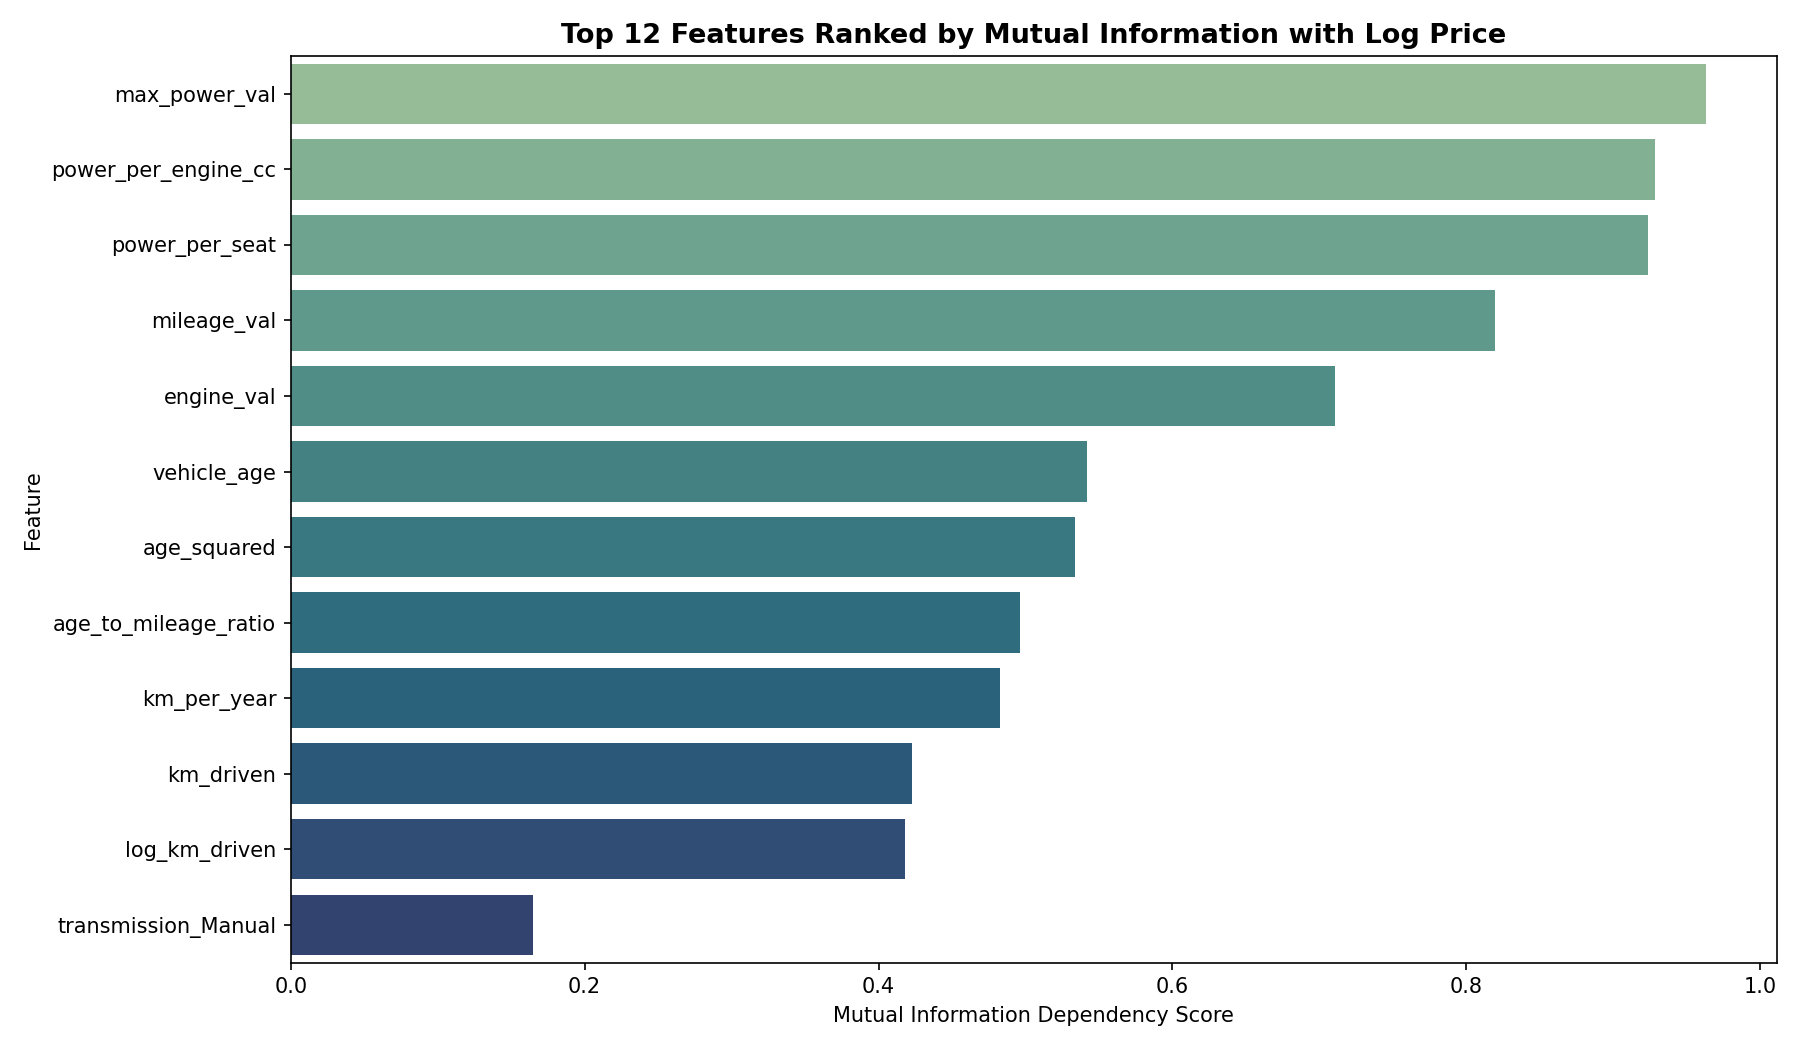

In [10]:
# Mutual Information Non-Linear Dependency Ranking


### 6. Train-Test Splitting & Feature Standardization ($Z$-Score)


In [11]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler

X = df_encoded[model_features].values
y = df_encoded['log_selling_price'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Instances : {X_train.shape[0]:,}")
print(f"Testing Instances  : {X_test.shape[0]:,}")


Training Instances : 6,502
Testing Instances  : 1,626


### 7. Hyperparameter Tuning via 5-Fold Cross-Validation (Ridge, Lasso, ElasticNet)


In [12]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor, RidgeCV, LassoCV, ElasticNetCV

alphas = np.logspace(-4, 4, 100)
cv_split = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_cv = RidgeCV(alphas=alphas, cv=cv_split, scoring='neg_mean_squared_error').fit(X_train_scaled, y_train)
lasso_cv = LassoCV(alphas=alphas, cv=cv_split, max_iter=10000, random_state=42).fit(X_train_scaled, y_train)
elastic_cv = ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.7, 0.9], cv=cv_split, max_iter=10000, random_state=42).fit(X_train_scaled, y_train)

print(f"Optimal Alpha Ridge (L2)       : {ridge_cv.alpha_:.4f}")
print(f"Optimal Alpha Lasso (L1)       : {lasso_cv.alpha_:.4f}")
print(f"Optimal ElasticNet (alpha, l1) : {elastic_cv.alpha_:.4f}, {elastic_cv.l1_ratio_}")


Optimal Alpha Ridge (L2)       : 8.4975
Optimal Alpha Lasso (L1)       : 0.0006
Optimal ElasticNet (alpha, l1) : 0.0006, 0.9000


<Figure size 1600x600 with 2 Axes>


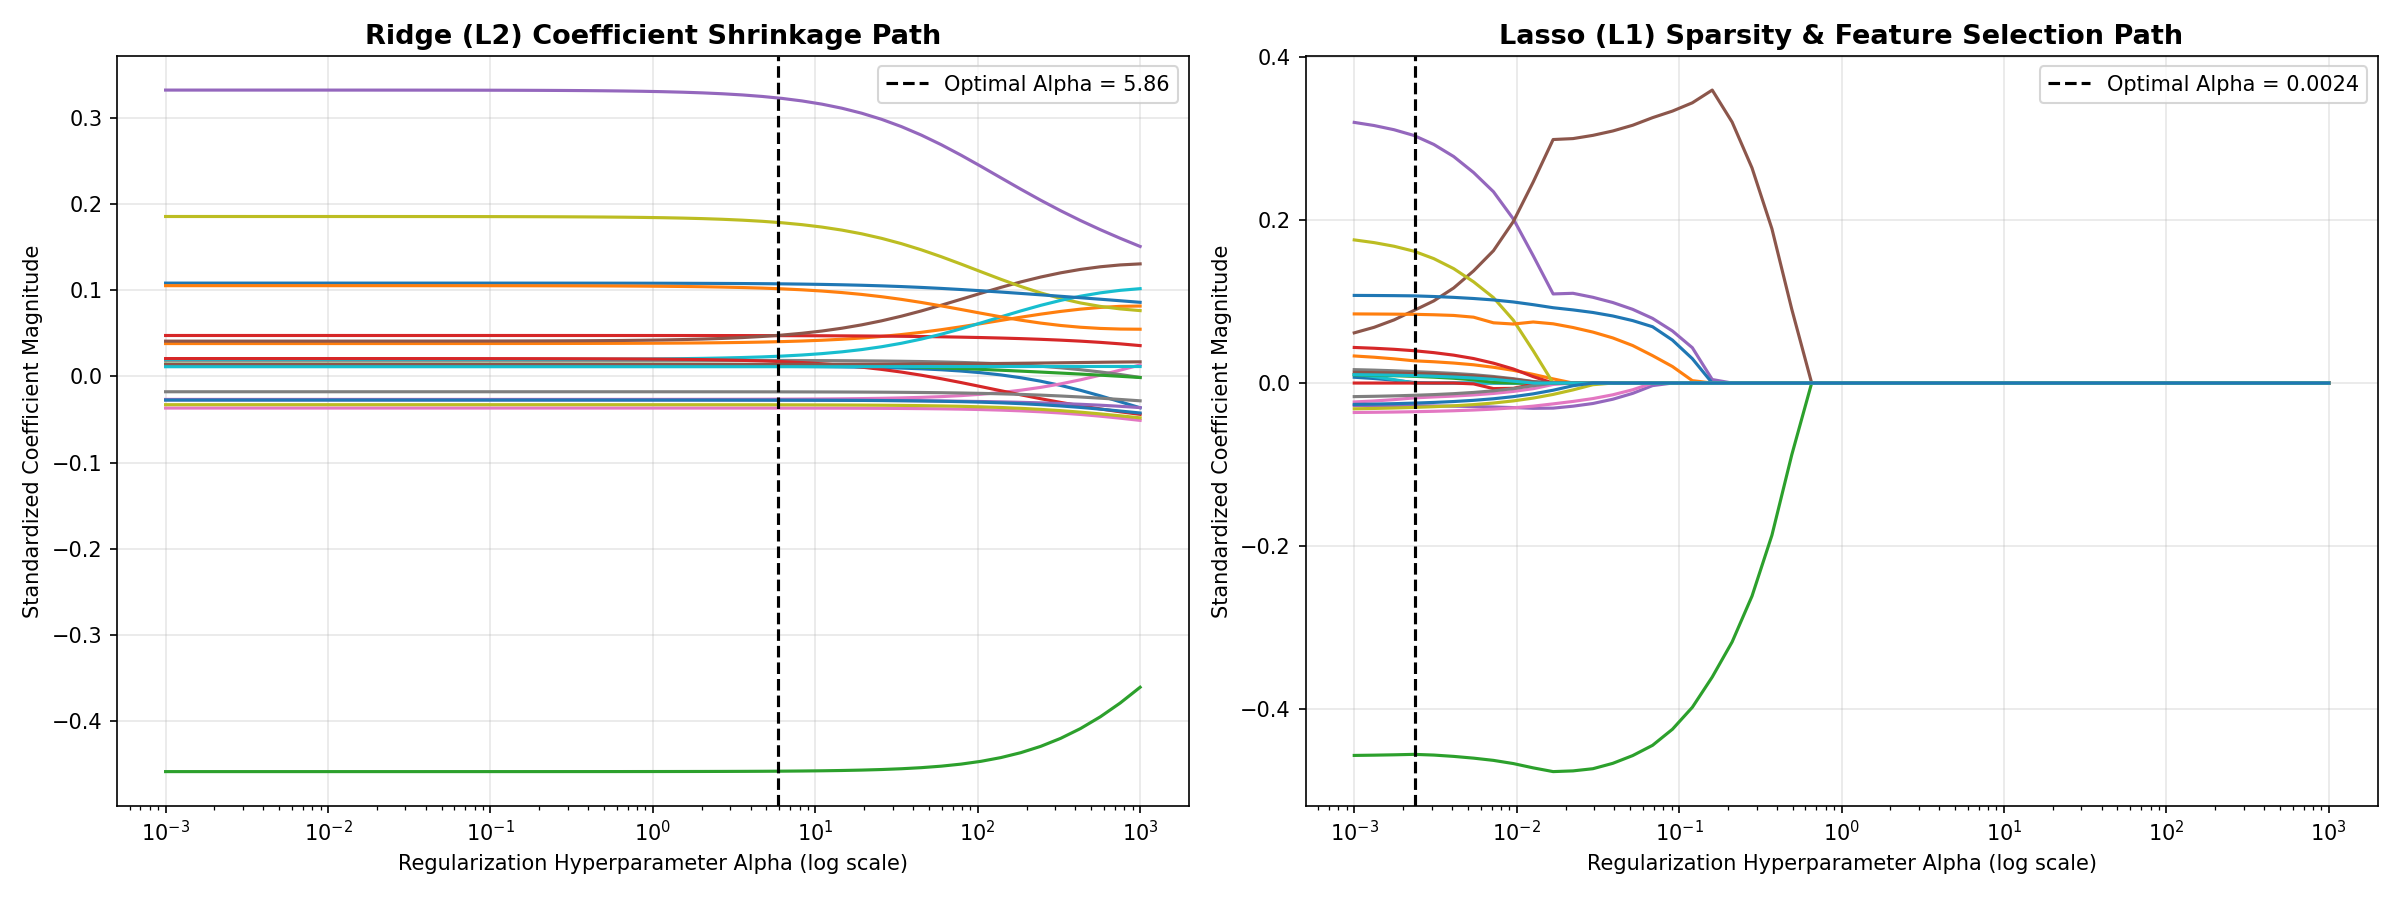

In [13]:
# Regularization Paths (Ridge vs Lasso Coefficient Shrinkage Traces)


<Figure size 1000x600 with 1 Axes>


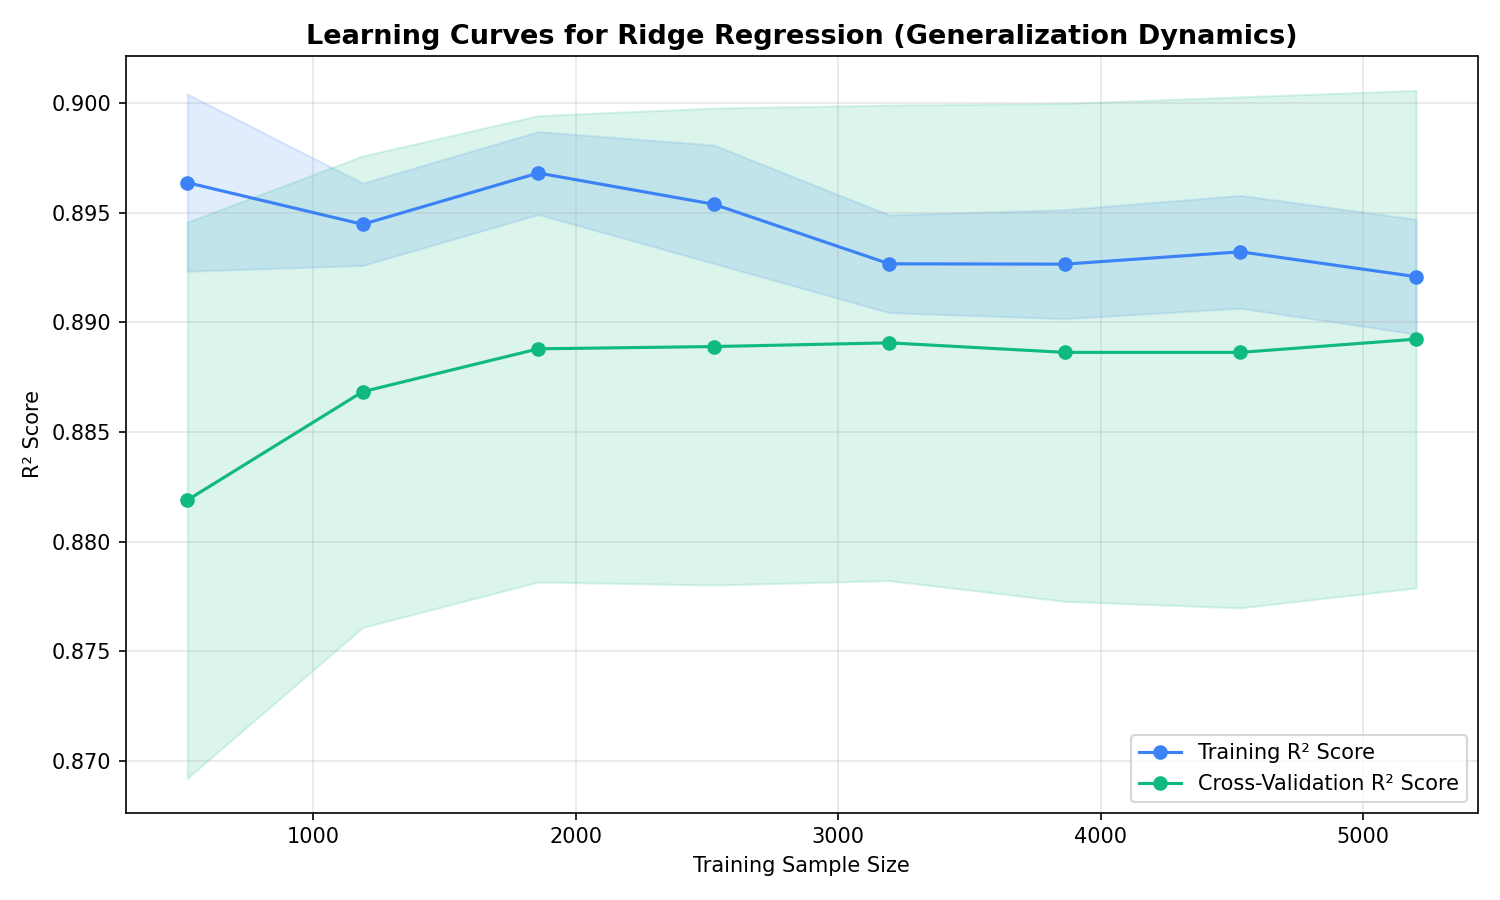

In [14]:
# Learning Curves: Evaluating Sample Complexity & Bias-Variance Tradeoff
